# ANALISIS EXPLORATORIO DE DATOS CON PANDAS DATASET: songs_2000_2020_50k.csv

Autoras: 

- Sara Margarita Gonzales Burgos 
- Eimy Edith Ramirez Fernandez 

- Materia: Analitica de Datos
- Objetivo: Aplicar tecnicas de analisis, limpieza, transformacion y exploracion de datos. 

Importacion de las librerias

In [3]:
import pandas as pd
import numpy as np

pd.set_option('display.max_columns', None)

Carga del Dataset

In [4]:
df = pd.read_csv("songs_2000_2020_50k.csv")

print("Dataset cargado correctamente")

Dataset cargado correctamente


Exploracion inicial 

In [5]:
df.head()

,Title,Artist,Album,Genre,Release Date,Duration,Popularity
0,Include name this.,Patrick Anderson,Care.,R&B,2008-01-09,262,71
1,Manage west energy.,Eric Miller,Raise get.,Jazz,2011-08-20,187,37
2,Evening court painting.,Richard Curry,Sport.,Electronic,2010-05-30,212,58
3,Section turn hour.,James Smith,Full.,Hip-Hop,2014-10-12,272,59
4,Five agreement teach.,Amy Rodriguez,Eat.,Blues,2005-06-09,131,34


In [6]:
df.tail()

,Title,Artist,Album,Genre,Release Date,Duration,Popularity
49995,Thing.,Brandon Thomas,Lawyer sign.,Rock,2008-06-07,300,95
49996,Option.,Barry White,Cold.,Pop,2016-09-06,220,23
49997,Ability ever.,Leah Obrien,Trade.,Blues,2013-10-16,257,79
49998,Occur claim who.,Ashley James,Explain moment.,Jazz,2018-03-06,262,22
49999,Value.,John Wong,Each.,Country,2002-11-26,203,70


In [7]:
print("Filas:", df.shape[0])
print("Columnas:", df.shape[1])

Filas: 50000
Columnas: 7


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   Title         50000 non-null  str  
 1   Artist        50000 non-null  str  
 2   Album         50000 non-null  str  
 3   Genre         50000 non-null  str  
 4   Release Date  50000 non-null  str  
 5   Duration      50000 non-null  int64
 6   Popularity    50000 non-null  int64
dtypes: int64(2), str(5)
memory usage: 2.7 MB


In [9]:
df.dtypes

Title             str
Artist            str
Album             str
Genre             str
Release Date      str
Duration        int64
Popularity      int64
dtype: object

In [10]:
df.describe()

,Duration,Popularity
count,50000.000000,50000.000000
mean,209.742900,50.263840
std,52.492824,29.142209
min,120.000000,0.000000
25%,164.000000,25.000000
50%,210.000000,50.000000
75%,255.000000,76.000000
max,300.000000,100.000000


Limpieza de Datos 

In [11]:
df.isnull().sum()

Title           0
Artist          0
Album           0
Genre           0
Release Date    0
Duration        0
Popularity      0
dtype: int64

In [12]:
(df.isnull().sum() / len(df)) * 100

Title           0.0
Artist          0.0
Album           0.0
Genre           0.0
Release Date    0.0
Duration        0.0
Popularity      0.0
dtype: float64

In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
df = df.drop_duplicates()

print("Duplicados eliminados")

Duplicados eliminados


In [15]:
columnas_numericas = df.select_dtypes(include=np.number).columns

columnas_numericas

Index(['Duration', 'Popularity'], dtype='str')

In [16]:
for columna in columnas_numericas:
    df[columna] = df[columna].fillna(df[columna].mean())

print("Valores numéricos corregidos")

Valores numéricos corregidos


In [17]:
columnas_categoricas = df.select_dtypes(include='object').columns

columnas_categoricas

C:\Users\Eimy\AppData\Local\Temp\ipykernel_8040\758409947.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  columnas_categoricas = df.select_dtypes(include='object').columns


Index(['Title', 'Artist', 'Album', 'Genre', 'Release Date'], dtype='str')

In [18]:
for columna in columnas_categoricas:
    moda = df[columna].mode()[0]
    df[columna] = df[columna].fillna(moda)

print("Valores categóricos corregidos")

Valores categóricos corregidos


In [19]:
df["Duration"].value_counts()

Duration
139    318
166    317
130    316
299    313
192    311
      ... 
214    246
124    243
223    243
224    240
183    222
Name: count, Length: 181, dtype: int64

In [20]:
df["Popularity"].value_counts()

Popularity
97    560
36    543
34    540
65    540
59    534
     ... 
47    459
40    458
3     456
48    455
21    442
Name: count, Length: 101, dtype: int64

In [21]:
df["Artist"].value_counts()

Artist
James Smith         23
Michael Johnson     21
Robert Johnson      20
Jessica Smith       19
Jennifer Johnson    18
                    ..
Madeline Dickson     1
Barry White          1
Leah Obrien          1
Ashley James         1
John Wong            1
Name: count, Length: 40156, dtype: int64

Transformacion de variables 

In [22]:
df["Grupo_Duracion"] = pd.cut(
    df["Duration"],
    bins=[0, 3, 6, 9, 12],
    labels=[
        "0-3 min",
        "3-6 min",
        "6-9 min",
        "9-12 min"
    ]
)

df[["Duration","Grupo_Duracion"]].head()

,Duration,Grupo_Duracion
0,262,NaN
1,187,NaN
2,212,NaN
3,272,NaN
4,131,NaN


In [23]:
df["Grupo_Popularidad"] = pd.cut(
    df["Popularity"],
    bins=[0,25,50,75,100],
    labels=[
        "Baja",
        "Media",
        "Alta",
        "Muy Alta"
    ]
)

df[["Popularity","Grupo_Popularidad"]].head()

,Popularity,Grupo_Popularidad
0,71,Alta
1,37,Media
2,58,Alta
3,59,Alta
4,34,Media


In [24]:
df["Grupo_Popularidad"].value_counts()

Grupo_Popularidad
Muy Alta    12504
Alta        12475
Media       12366
Baja        12195
Name: count, dtype: int64

Deteccion de Outliers

In [25]:
df["Popularity"].mean()

np.float64(50.26384)

In [26]:
df["Duration"].mean()

np.float64(209.7429)

In [27]:
df.groupby("Duration")["Popularity"].mean()

Duration
120    49.946154
121    47.977528
122    46.955556
123    50.525926
124    50.436214
         ...    
296    48.969283
297    49.870229
298    49.105455
299    46.233227
300    51.121212
Name: Popularity, Length: 181, dtype: float64

In [28]:
df.groupby("Genre")["Popularity"].mean()

Genre
Blues         49.519506
Classical     50.686042
Country       50.264297
Electronic    49.794686
Hip-Hop       49.967018
Jazz          50.630694
Pop           50.397732
R&B           50.426302
Reggae        50.862920
Rock          50.112618
Name: Popularity, dtype: float64

In [29]:
df.groupby("Grupo_Duracion")["Popularity"].mean()

Series([], Name: Popularity, dtype: float64)

In [30]:
Q1 = df["Popularity"].quantile(0.25)
Q3 = df["Popularity"].quantile(0.75)

IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print("Límite inferior:", limite_inferior)
print("Límite superior:", limite_superior)

Límite inferior: -51.5
Límite superior: 152.5


In [31]:
outliers = df[
    (df["Popularity"] < limite_inferior) |
    (df["Popularity"] > limite_superior)
]

outliers

,Title,Artist,Album,Genre,Release Date,Duration,Popularity,Grupo_Duracion,Grupo_Popularidad


In [32]:
print("Outliers encontrados:", len(outliers))

Outliers encontrados: 0


Exportacion del Dataset Limpio 

In [33]:
print("Outliers encontrados:", len(outliers))

Outliers encontrados: 0


In [34]:
df.to_csv(
    "songs_2000_2020_50k_limpio.csv",
    index=False
)

print("Archivo exportado correctamente")

Archivo exportado correctamente


In [35]:
print("""
CONCLUSIONES

1. Se importó correctamente el Dataset de 319,050 registros.
2. Se identifico que solo Grupo_Horario tenia 4.73% de datos nulos.
3. Se aplicaron técnicas de limpieza de datos.
4. Se generaron nuevas variables mediante transformación.
5. Se crearon Grupo_Temporada y Grupo_Horario para analizar la relacion de ocuurencia de crimenes 
en diferentes horarios y temporadas.
6. Se identificaron valores atípicos utilizando IQR.
7. Se generó un nuevo dataset limpio para futuros análisis.
""")


CONCLUSIONES

1. Se importó correctamente el Dataset de 319,050 registros.
2. Se identifico que solo Grupo_Horario tenia 4.73% de datos nulos.
3. Se aplicaron técnicas de limpieza de datos.
4. Se generaron nuevas variables mediante transformación.
5. Se crearon Grupo_Temporada y Grupo_Horario para analizar la relacion de ocuurencia de crimenes 
en diferentes horarios y temporadas.
6. Se identificaron valores atípicos utilizando IQR.
7. Se generó un nuevo dataset limpio para futuros análisis.



Visualizacion 

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

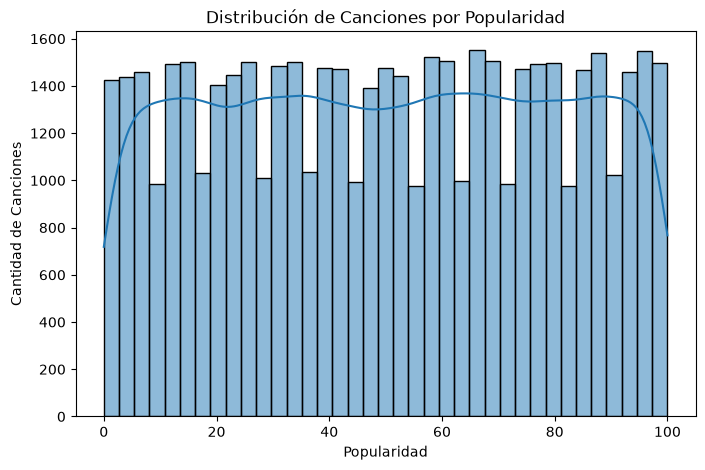

In [37]:
plt.figure(figsize=(8,5))
sns.histplot(df["Popularity"], kde=True)
plt.title("Distribución de Canciones por Popularidad")
plt.xlabel("Popularidad")
plt.ylabel("Cantidad de Canciones")
plt.show()

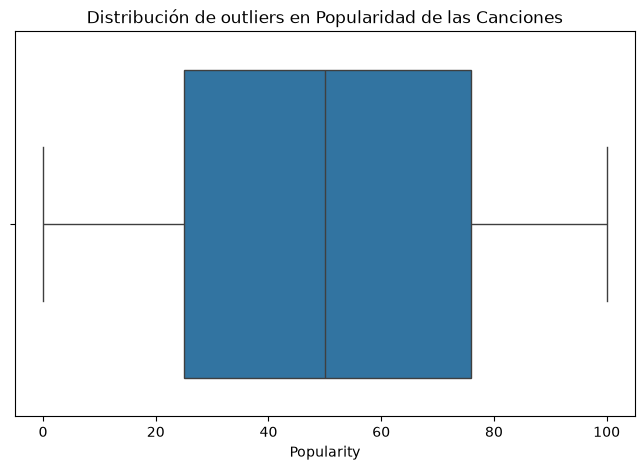

In [38]:
plt.figure(figsize=(8,5))
sns.boxplot(x=df["Popularity"])
plt.title("Distribución de outliers en Popularidad de las Canciones")
plt.show()

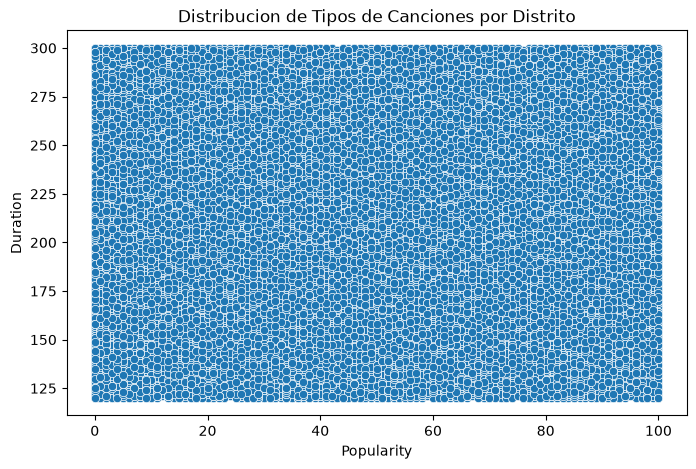

In [39]:
plt.figure(figsize=(8,5))
sns.scatterplot(
    x="Popularity",
    y="Duration",
    data=df
)
plt.title("Distribucion de Tipos de Canciones por Distrito")
plt.show()

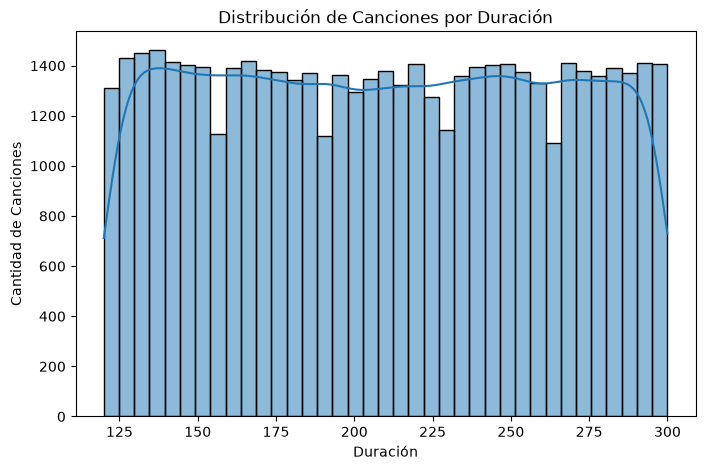

In [40]:
plt.figure(figsize=(8,5))
sns.histplot(df["Duration"], kde=True)
plt.title("Distribución de Canciones por Duración")
plt.xlabel("Duración")
plt.ylabel("Cantidad de Canciones")
plt.show()

C:\Users\Eimy\AppData\Local\Temp\ipykernel_8040\4131894437.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_genero.values, y=top_genero.index, palette="rocket")


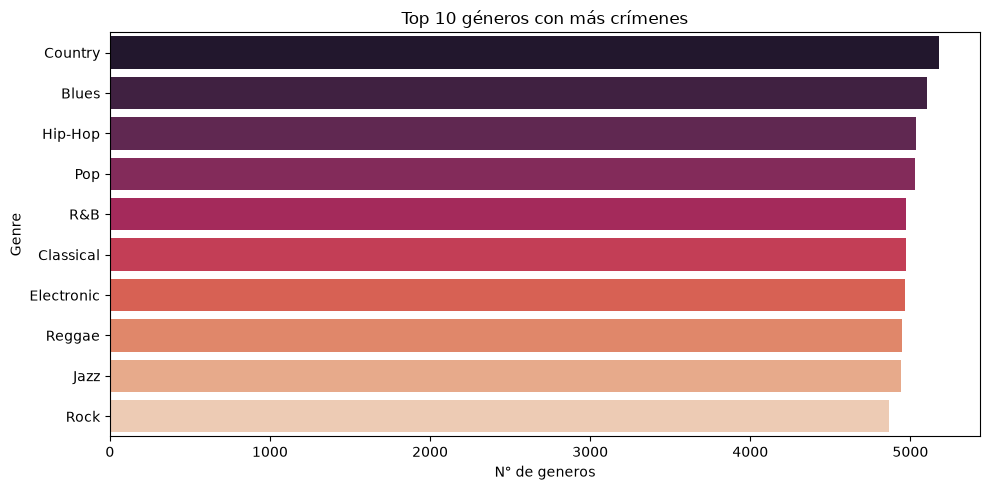

In [41]:
top_genero = df["Genre"].value_counts().head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=top_genero.values, y=top_genero.index, palette="rocket")
plt.title("Top 10 géneros con más crímenes")
plt.xlabel("N° de generos")
plt.tight_layout()
plt.show()

In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns


from scipy.signal import periodogram

plt.style.use('ggplot')

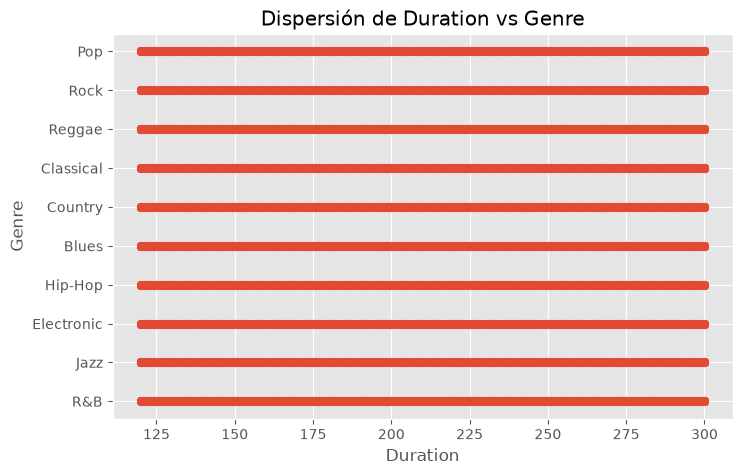

In [43]:
plt.figure(figsize=(8,5))
plt.scatter(df["Duration"], df["Genre"], alpha=0.5)

plt.title("Dispersión de Duration vs Genre")
plt.xlabel("Duration")
plt.ylabel("Genre")
plt.show()


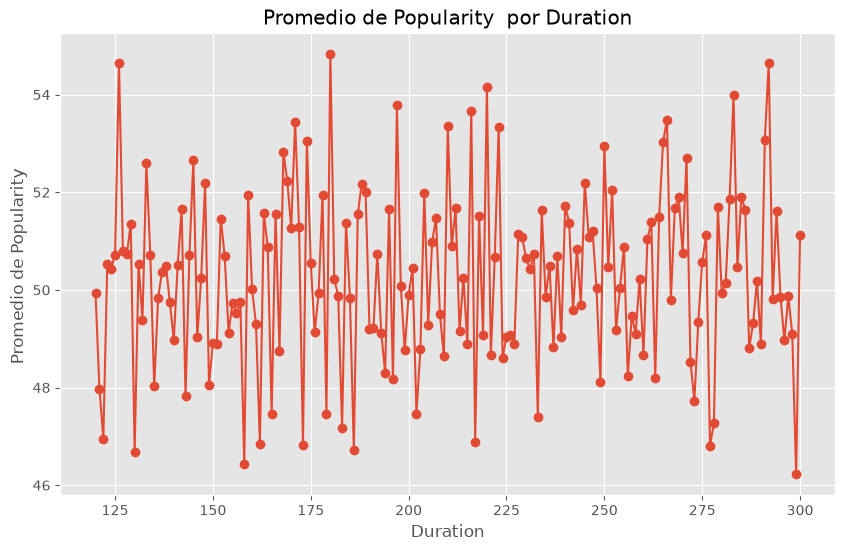

In [44]:
fare_class = df.groupby("Duration")["Popularity"].mean()

plt.figure(figsize=(10,6))
plt.plot(fare_class.index,
         fare_class.values,
         marker='o',
         linestyle='-',)

plt.title("Promedio de Popularity  por Duration")
plt.xlabel("Duration")  
plt.ylabel("Promedio de Popularity ")
plt.show()

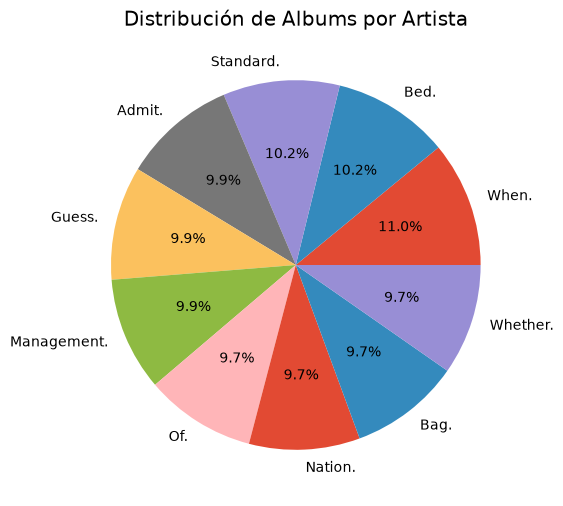

In [45]:
Album_counts = df["Album"].value_counts()

plt.figure(figsize=(10,6))
plt.pie(Album_counts.head(10),
        labels=Album_counts.head(10).index,
        autopct='%1.1f%%')

plt.title("Distribución de Albums por Artista")
plt.show()

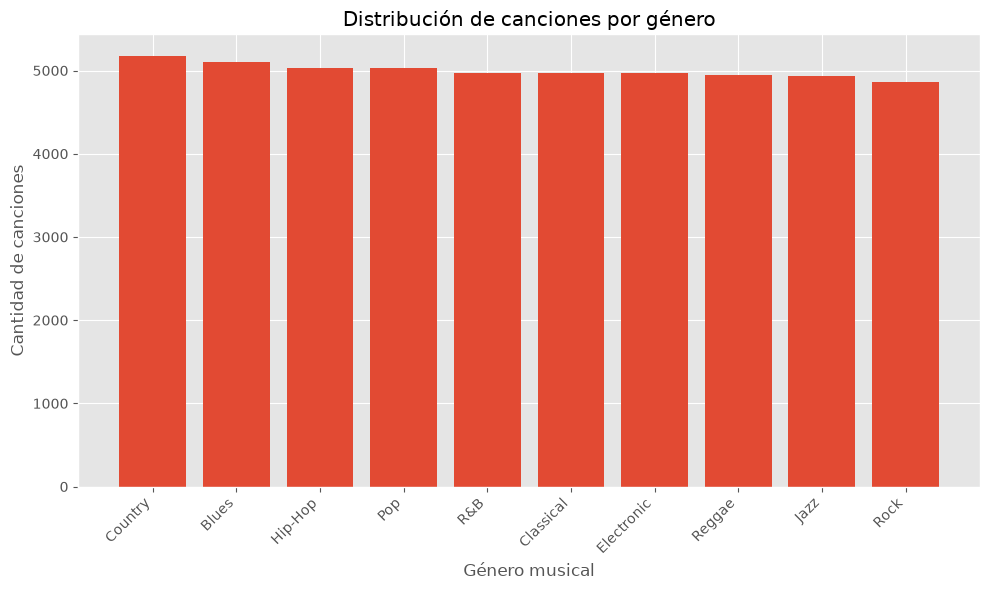

In [46]:
class_counts = df["Genre"].value_counts().head(10)

plt.figure(figsize=(10, 6))
plt.bar(class_counts.index.astype(str), class_counts.values)

plt.title("Distribución de canciones por género")
plt.xlabel("Género musical")
plt.ylabel("Cantidad de canciones")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

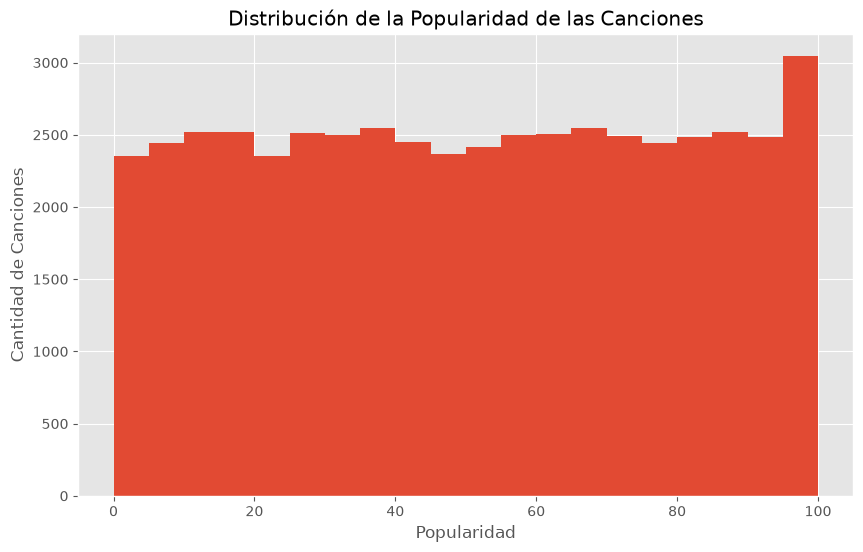

In [47]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.hist(df["Popularity"].dropna(), bins=20)

plt.title("Distribución de la Popularidad de las Canciones")
plt.xlabel("Popularidad")
plt.ylabel("Cantidad de Canciones")
plt.show()

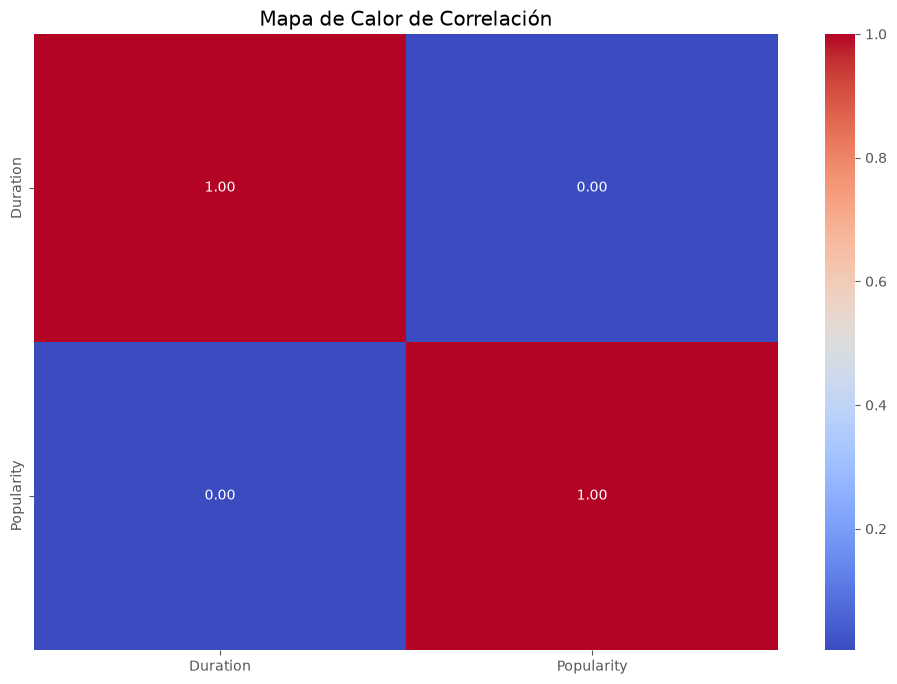

In [48]:
numeric_df = df.select_dtypes(include=np.number)

corr = numeric_df.corr()

plt.figure(figsize=(12,8))
sns.heatmap(corr, 
            annot=True, 
            fmt=".2f", 
            cmap="coolwarm",
)  

plt.title("Mapa de Calor de Correlación")
plt.show()


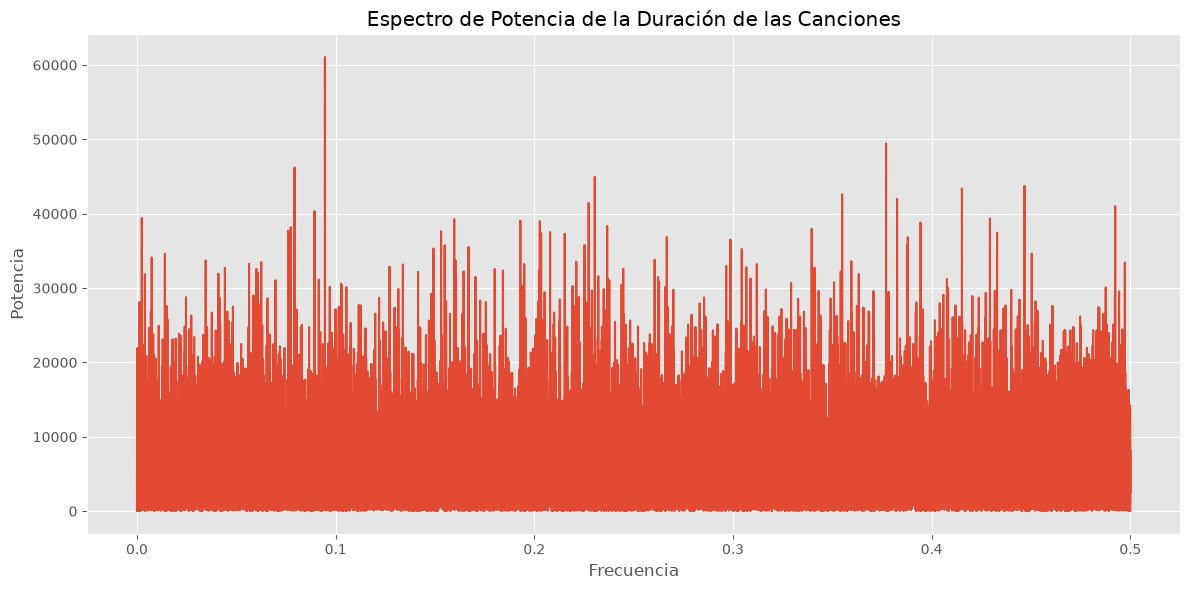

In [49]:
import matplotlib.pyplot as plt
from scipy.signal import periodogram

signal = df["Duration"].dropna().to_numpy()

frequencies, power_spectrum = periodogram(signal)

plt.figure(figsize=(12, 6))
plt.plot(frequencies, power_spectrum)

plt.xlabel("Frecuencia")
plt.ylabel("Potencia")
plt.title("Espectro de Potencia de la Duración de las Canciones")
plt.tight_layout()
plt.show()